In [18]:
import SimpleITK as sitk
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import json


In [ ]:
img_path = Path ("/workspaces/segmentation/data/input/QUADRA_HC_021/retest_CT-AC.nii.gz")
img = sitk.ReadImage(img_path)

In [2]:
t12_mask_dir = Path ("/workspaces/segmentation/data/output/QUADRA_HC_021/retest/small_bowel.nii.gz")
t12_mask = sitk.ReadImage(t12_mask_dir)

In [7]:
def show_overlay (img, mask):
    py_img = sitk.GetArrayFromImage(img)
    py_mask = sitk.GetArrayFromImage(mask)

    visible_mask = np.ma.masked_where(py_mask == 0, py_mask)

    plt.imshow(py_img, cmap="gray")
    plt.imshow(visible_mask, cmap="autumn", alpha=0.5, vmin=0, vmax=1)
    plt.axis("off")
    plt.show()

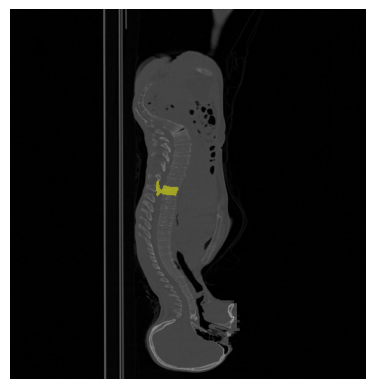

In [8]:
show_overlay (img[263,:,:], t12_mask[263,:,:])

In [3]:
mask_array = sitk.GetArrayFromImage(t12_mask)
mask_value = np.unique(mask_array)
mask_value

array([0, 1], dtype=uint8)

In [3]:
components = sitk.ConnectedComponent(t12_mask, False)

In [4]:
inspector = sitk.RelabelComponentImageFilter()
inspector.Execute(components)

component_size = inspector.GetSizeOfObjectsInPixels()

print (component_size)



(73749, 126, 59, 30, 7, 5, 5, 5, 4, 3, 3, 3, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1)


In [5]:
max(component_size)

73749

In [5]:
threshold = max(component_size) * 0.01 

int (threshold)

737

In [6]:
filter = sitk.RelabelComponentImageFilter()
filter.SetMinimumObjectSize(int(threshold))
retained_components = filter.Execute(components)
filtered_mask = retained_components > 0


In [ ]:
mask_array = sitk.GetArrayFromImage(filtered_mask)
mask_value = np.unique(mask_array)
mask_value

In [ ]:
get_properties(retained_components)

In [ ]:
get_properties(filtered_mask)


In [20]:
def get_properties (img):

    img_data = {
        "img_dimension" : img.GetDimension(),
        "img_size" : img.GetSize(),
        "img_orign" : img.GetOrigin(),
        "img_spacing" : img.GetSpacing(),
        "img_direction" : img.GetDirection(),
    }

    return img_data

In [9]:
output_dir = Path("/workspace/segmentation/data/output")

In [ ]:
region_size = {}

for subject_dir in sorted(output_dir.iterdir()): #iterate through all subjects
    if not subject_dir.is_dir():
        continue 

    subject_name = subject_dir.name
    region_per_subject = {}
    
    for session_dir in sorted(subject_dir.iterdir()): #iterate thorugh all sessions
        if not session_dir.is_dir():
            continue

        session_name = session_dir.name
        region_per_session = {}
        mask_dirs = sorted(session_dir.glob("*.nii.gz"))

        for mask_dir in mask_dirs:
            mask_name = mask_dir.name.removesuffix(".nii.gz")
            mask = sitk.ReadImage(mask_dir)

            components = sitk.ConnectedComponent(mask, False)
            
            inspector = sitk.RelabelComponentImageFilter()
            inspector.Execute(components)
            component_size = inspector.GetSizeOfObjectsInPixels()

            region_per_session[mask_name] = component_size

        region_per_subject[session_name] = region_per_session

    region_size[subject_name] = region_per_subject



for patient, content in region_size.items():
    print(f"'{patient}':")
    for key, val in content.items():
        print(f"  > '{key}':")
        for organ, sizes in val.items():
            print(f"    > '{organ}': {sizes}")

{'QUADRA_HC_021': {'retest': {'brain': (280789,),
   'carnial_spinal_cord': (5975,),
   'colon': (189423, 20281, 834, 302, 2),
   'duodenum': (2539, 2101, 325, 1),
   'esophagus': (4815,),
   'eye_left': (2073,),
   'eye_right': (2083,),
   'heart': (117419, 2, 2, 2, 1, 1, 1, 1, 1, 1),
   'hip_left': (78178,),
   'hip_right': (76818,),
   'kidney_left': (14403,),
   'kidney_right': (20460,),
   'liver': (377452, 1, 1),
   'lung_lower_lobe_left': (123018, 17, 1, 1, 1),
   'lung_lower_lobe_right': (145960, 1, 1),
   'lung_middle_lobe_right': (62349, 2),
   'lung_upper_lobe_left': (152543,),
   'lung_upper_lobe_right': (134373,),
   'optic_nerve_left': (76,),
   'optic_nerve_right': (100,),
   'pancreas': (6639, 62, 3),
   'parotid_gland_left': (2523,),
   'parotid_gland_right': (2288,),
   'rib_left_6': (4191, 5, 1, 1, 1, 1),
   'rib_right_6': (4205,),
   'sacrum': (46749, 15, 14, 8, 7, 7, 6, 5, 4, 2, 2, 1, 1, 1, 1, 1, 1),
   'skull': (166908, 47, 41, 1, 1, 1, 1),
   'small_bowel': (7374

In [16]:
#writing json report
def write_report_json (parameters):
    json_dir = "/workspace/segmentation/data/output/component_count.json"
    json_path = Path(json_dir)

    #get the written parameters
    if json_path.exists() and json_path.stat().st_size > 0 :
        with open (json_path, "r", encoding="utf-8") as file:
            try:
                current_data = json.load(file)
                if not isinstance(current_data, list):
                    current_data = []
            except json.JSONDecodeError:
                current_data = []
    else:
        current_data = []

    # add the current parameters to the written parameters (to update the parameters)
    current_data.append(parameters)

    with open(json_path, "w", encoding="utf-8") as file:
        json.dump(current_data, file, indent=4)

In [19]:
region_size = {}

for subject_dir in sorted(output_dir.iterdir()): #iterate through all subjects
    if not subject_dir.is_dir():
        continue 

    subject_name = subject_dir.name
    region_per_subject = {}
    
    for session_dir in sorted(subject_dir.iterdir()): #iterate thorugh all sessions
        if not session_dir.is_dir():
            continue

        session_name = session_dir.name
        region_per_session = {}
        mask_dirs = sorted(session_dir.glob("*.nii.gz"))

        for mask_dir in mask_dirs:
            mask_name = mask_dir.name.removesuffix(".nii.gz")
            mask = sitk.ReadImage(mask_dir)
            components = sitk.ConnectedComponent(mask, False)
            inspector = sitk.RelabelComponentImageFilter()
            inspector.Execute(components)
            component_size = inspector.GetSizeOfObjectsInPixels()

            blob = max(component_size) * 0.01 
            threshold = max(blob, 3) 

            filter = sitk.RelabelComponentImageFilter()
            filter.SetMinimumObjectSize(int(threshold))
            retained_components = filter.Execute(components)
            filtered_mask = retained_components > 0

            filtered_component_size = filter.GetSizeOfObjectsInPixels()

            filtered_dir = Path(*("filtered" if part == "output" else part for part in mask_dir.parts))
            filtered_dir.parent.mkdir(parents=True, exist_ok=True)

            sitk.WriteImage(filtered_mask, filtered_dir)

            region_per_session[mask_name] = filtered_component_size
            

        region_per_subject[session_name] = region_per_session

    region_size[subject_name] = region_per_subject



# for patient, content in region_size.items():
#     print(f"'{patient}':")
#     for key, val in content.items():
#         print(f"  > '{key}':")
#         for organ, sizes in val.items():
#             print(f"    > '{organ}': {sizes}")

write_report_json(region_size)

In [21]:
filtered_mask_dir = "/workspace/segmentation/data/filtered/QUADRA_HC_001/retest/brain.nii.gz"
filtered_mask = sitk.ReadImage(filtered_mask_dir)

In [22]:
get_properties (filtered_mask)

{'img_dimension': 3,
 'img_size': (512, 512, 531),
 'img_orign': (-389.23828125, 247.23828125, -1095.0),
 'img_spacing': (1.5234375, 1.5234375, 2.0),
 'img_direction': (1.0, 0.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 1.0)}

In [23]:
img = sitk.ReadImage("/workspace/segmentation/data/input/QUADRA_HC_001/retest_CT-AC.nii.gz")

In [24]:
get_properties(img)

{'img_dimension': 3,
 'img_size': (512, 512, 531),
 'img_orign': (-389.23828125, 247.23828125, -1095.0),
 'img_spacing': (1.5234375, 1.5234375, 2.0),
 'img_direction': (1.0, 0.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 1.0)}